# Analysis on the "EEG during arithmetic task' dataset"

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from pce import pc_entropy

In [ ]:
from nbutils import ImageSaver, set_plt_params

set_plt_params()
# set save_imgs to False to avoid saving images
ims = ImageSaver(save_imgs=True)


In [ ]:
import physionet
from pathlib import Path

DATA_DIR = Path("eegmat-1.0.0")

# Download the database if not already present
if not DATA_DIR.exists():
    physionet.download("eegmat", version="1.0.0", output_dir=str(DATA_DIR))

In [ ]:
info = physionet.load("eegmat", table="subject-info", version="1.0.0")
info

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality
0,Subject00,21,F,2011,9.70,0
1,Subject01,18,F,2011,29.35,1
2,Subject02,19,F,2012,12.88,1
3,Subject03,17,F,2010,31.00,1
4,Subject04,17,F,2010,8.60,0
5,Subject05,16,F,2010,20.71,1
6,Subject06,18,M,2011,4.35,0
7,Subject07,18,F,2012,13.38,1
8,Subject08,26,M,2011,18.24,1
9,Subject09,16,F,2010,7.00,0


In [ ]:
from pathlib import Path
from pyedflib import highlevel
import pandas as pd

DATA_DIR = Path("eegmat-1.0.0")

def load_subject_edf(subject_number: int, condition: int):
    DATA_DIR = Path("eegmat-1.0.0")

    if not 0 <= subject_number <= 35:
        raise RuntimeError('Subject number must be between 0 and 35 (included)')

    if condition != 1 and condition != 2:
        raise RuntimeError('Condition must be either 1 (rest) or 2 (arithmetic task)')

    signals, signal_headers, header = highlevel.read_edf(str(DATA_DIR / f'Subject{subject_number:02d}_{condition}.edf'))
    fs = signal_headers[0]["sample_frequency"]
    labels = [signal_header['label'] for signal_header in signal_headers]
    return signals, fs, labels

def build_table(condition: str | int) -> pd.DataFrame:
    valid_conditions = {'rest': 1, 'arithmetic task': 2}
    
    if isinstance(condition, str) and condition not in valid_conditions.keys():
        raise RuntimeError("Condition must be either 'rest' or 'arithmetic task'")

    if isinstance(condition, str): condition = valid_conditions[condition]

    rows = []
    for i, subject in enumerate(info.Subject):
        signals, fs, labels = load_subject_edf(subject_number=int(i), condition=condition)
        rows.append({'Subject': subject, 'fs':fs, 'labels': labels,  'eeg': signals[:19]})

    return info.merge(pd.DataFrame(rows), on='Subject')

In [ ]:
signals, signal_headers, header = highlevel.read_edf(str(DATA_DIR / f'Subject{0:02d}_{1}.edf'))
[signal_header['label'] for signal_header in signal_headers]

['EEG Fp1',
 'EEG Fp2',
 'EEG F3',
 'EEG F4',
 'EEG F7',
 'EEG F8',
 'EEG T3',
 'EEG T4',
 'EEG C3',
 'EEG C4',
 'EEG T5',
 'EEG T6',
 'EEG P3',
 'EEG P4',
 'EEG O1',
 'EEG O2',
 'EEG Fz',
 'EEG Cz',
 'EEG Pz',
 'EEG A2-A1',
 'ECG ECG']

In [ ]:
eegs_rest_df = build_table('rest')
eegs_rest_df.head()

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality,fs,labels,eeg
0,Subject00,21,F,2011,9.70,0,500.0,"[EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG...","[[-3.647938, -4.236482, -4.954218, -5.703854, ..."
1,Subject01,18,F,2011,29.35,1,500.0,"[EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG...","[[-6.347912, -5.884709, -5.160955, -4.313504, ..."
2,Subject02,19,F,2012,12.88,1,500.0,"[EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG...","[[-1.489817, -3.51847, -5.22801, -6.166703, -6..."
3,Subject03,17,F,2010,31.00,1,500.0,"[EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG...","[[5.887305, 4.211407, 2.132053, -0.079719, -2...."
4,Subject04,17,F,2010,8.60,0,500.0,"[EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG...","[[-6.645441, -6.435402, -6.276706, -6.234698, ..."


In [ ]:
eegs_arithmetic_df = build_table('arithmetic task')
eegs_arithmetic_df.head()

,Subject,Age,Gender,Recording year,Number of subtractions,Count quality,fs,labels,eeg
0,Subject00,21,F,2011,9.70,0,500.0,"[EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG...","[[4.476049, 1.208021, -2.546008, -6.187074, -9..."
1,Subject01,18,F,2011,29.35,1,500.0,"[EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG...","[[13.990337, 12.876663, 11.885061, 11.246529, ..."
2,Subject02,19,F,2012,12.88,1,500.0,"[EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG...","[[3.52582, 2.5774, 0.958405, -0.975839, -2.584..."
3,Subject03,17,F,2010,31.00,1,500.0,"[EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG...","[[5.035679, 3.356242, 0.928292, -2.09721, -5.3..."
4,Subject04,17,F,2010,8.60,0,500.0,"[EEG Fp1, EEG Fp2, EEG F3, EEG F4, EEG F7, EEG...","[[1.172364, 1.752832, 2.449393, 3.077459, 3.35..."


In [ ]:
eegs_rest_df['eeg'].apply(np.shape).value_counts()

eeg
(19, 91000)    33
(19, 85000)     1
(19, 94000)     1
(19, 40000)     1
Name: count, dtype: int64

In [ ]:
eegs_arithmetic_df['eeg'].apply(np.shape).value_counts()

eeg
(19, 31000)    36
Name: count, dtype: int64

In [ ]:
# check of the sampling frequency
EEG_FS = 500
eegs_rest_df['fs'].value_counts(), eegs_arithmetic_df['fs'].value_counts()

(fs
 500.0    36
 Name: count, dtype: int64,
 fs
 500.0    36
 Name: count, dtype: int64)

In [ ]:
def get_matrix(df: pd.DataFrame, seconds=60, fs=500) -> np.ndarray:
    N = seconds * fs
    array = np.stack([x[: , :N] for x in df['eeg']])
    return np.swapaxes(array, -1, -2)

In [ ]:
eegs_rest = get_matrix(eegs_rest_df)
eegs_arithmetic = get_matrix(eegs_arithmetic_df)

assert eegs_rest.shape == eegs_arithmetic.shape and eegs_arithmetic.shape == (36, 30000, 19)

In [ ]:
# Filter design

from scipy.signal import firwin

def fir_bandpass(l_freq: float, h_freq: float, fs: float, trans: float, window: str='hamming') -> np.ndarray:
    constants = {
        'rectangular': 0.9,
        'bartlett': 2.9,
        'hann': 3.1,
        'hamming': 3.3,
        'blackman': 5.5
    }

    if window not in constants.keys():
        raise RuntimeError(f'Invalid window name {window} select one within {constants.keys()}')
    
    # Δω = 2πΔf / fs
    # Δω = c2π / L
    # 2πfs / f = cπ / L
    # L = 0.5c f / fs
    
    c = constants[window]

    L = int(np.ceil(c * fs / trans)) | 1

    return np.asarray(firwin(
        numtaps=L,
        cutoff=[l_freq - trans / 2, h_freq + trans / 2],
        pass_zero=False,      # band-pass
        fs=fs,
        window=window
    ))

In [ ]:
from typing import NamedTuple

# filters
WINDOW = 'hamming'
EEG_WAVES = ('delta', 'theta', 'alpha', 'beta', 'gamma')

delta, theta, alpha, beta, gamma = EEG_WAVES

class WaveFIRConfig(NamedTuple):
    l_freq: float
    h_freq: float
    trans: float
wave_fir_configs = {
    delta: WaveFIRConfig(l_freq=1, h_freq=4, trans=1),
    theta: WaveFIRConfig(l_freq=4,h_freq=8, trans=2),
    alpha: WaveFIRConfig(l_freq=8, h_freq=13, trans=2),
    beta: WaveFIRConfig(l_freq=13, h_freq=30, trans=3.25),
    gamma: WaveFIRConfig(l_freq=30,h_freq=45,trans=3)
}

waves_filters = {
    wave: fir_bandpass(
    l_freq=config.l_freq,
    h_freq=config.h_freq,
    fs=EEG_FS,
    trans=config.trans,
    window=WINDOW,    
    ) for wave, config in wave_fir_configs.items()
}

In [ ]:
from scipy.signal import fftconvolve

def filter_wave(x: np.ndarray, h: np.ndarray, axis=-2):
    shape = [1] * x.ndim
    shape[axis] = -1

    delay = (h.shape[0] - 1) // 2 
    pad = [(0, 0)] * x.ndim
    pad[axis] = (delay, delay)
    xp = np.pad(x, pad, mode='reflect', reflect_type='odd')
    return fftconvolve(xp, h.reshape(shape), mode='valid', axes=axis)

In [ ]:
from typing import Dict

def filter_eeg_by_wave_bands(eeg: np.ndarray) -> Dict[str, np.ndarray]:
    return {
        wave: filter_wave(eeg, f)
        for wave, f in waves_filters.items()
    }

In [ ]:
eegs_rest_waves = filter_eeg_by_wave_bands(eegs_rest)
eegs_arithmetic_waves = filter_eeg_by_wave_bands(eegs_arithmetic)

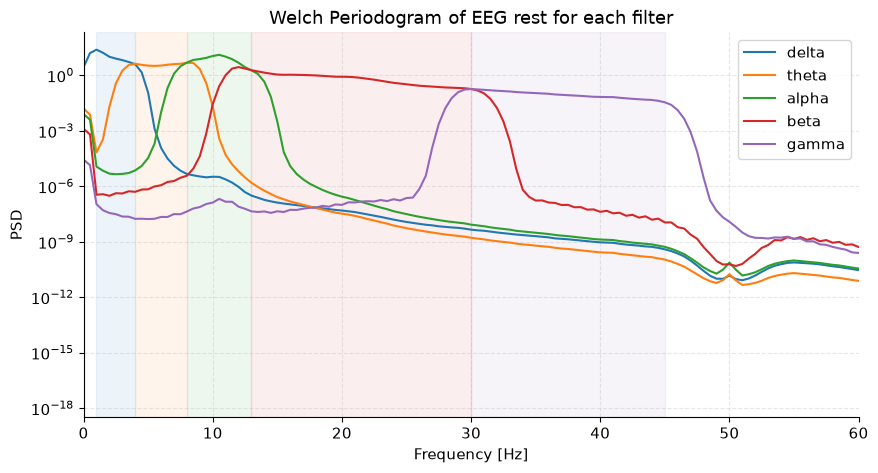

In [ ]:
from scipy.signal import welch
fig, ax = plt.subplots(figsize=(10, 5))
for name, cfg in wave_fir_configs.items():
    fs = 500
    f, P = welch(eegs_rest_waves[name], fs=fs, nperseg=1000, axis=-2)
    line, = ax.semilogy(f, P.mean(axis=(0, -1)), label=name)
    ax.axvspan(cfg.l_freq, cfg.h_freq, color=line.get_color(), alpha=0.08)

ax.set_xlim(0, 60)
ax.set_xlabel("Frequency [Hz]"); 
ax.set_ylabel("PSD")
ax.set_title('Welch Periodogram of EEG rest for each filter')
ax.legend() 
ims.save_img('welch-periodogram-rest.png')
plt.show()

In [ ]:
def pc_entropy_sliding_window(x: np.ndarray, fs: float, samples_count=5, window_length=10):
    avg5 = np.lib.stride_tricks.sliding_window_view(x, axis=1, window_shape=samples_count)[:, ::samples_count, :].mean(axis=-1)

    fs= fs/samples_count
    w=int(window_length*fs)
    avg10 = avg5.reshape(x.shape[0], -1, w, x.shape[-1])
    pce6 = pc_entropy(avg10)
    return pce6.mean(axis=-1)

In [ ]:
pce_rest_waves = {
    wave: pc_entropy_sliding_window(eeg, EEG_FS) 
    for wave, eeg in eegs_rest_waves.items()
}

pce_arithmetic_waves = {
    wave: pc_entropy_sliding_window(eeg, EEG_FS) 
    for wave, eeg in eegs_arithmetic_waves.items()
}

In [ ]:
from typing import Dict, Tuple

good_counters = info['Count quality'].to_numpy(dtype=bool)
bad_counters = ~good_counters

def split_poor_good(x: Dict[str, np.ndarray], good_counters: np.ndarray) -> Tuple[Dict[str, np.ndarray], Dict[str, np.ndarray]]:
    
    x_gc_waves = {
        wave: pce[good_counters]
        for wave, pce in x.items() 
    }

    x_pc_waves = {
        wave: pce[bad_counters]
        for wave, pce in x.items()
    }

    return x_gc_waves, x_pc_waves

pce_rest_gc_waves, pce_rest_pc_waves = split_poor_good(x=pce_rest_waves, good_counters=good_counters)
pce_arithmetic_gc_waves, pce_arithmetic_pc_waves = split_poor_good(x=pce_arithmetic_waves, good_counters=good_counters)

In [ ]:
from scipy.stats import wilcoxon, false_discovery_control

Q_THRESHOLD = 0.05

def measure_differences(x, y, keys, threshold=Q_THRESHOLD):
    pvals = np.array([wilcoxon(x[wave], y[wave]).pvalue for wave in keys])
    qvals = false_discovery_control(pvals)

    return {(k, p, q) for k, p, q in zip(keys, pvals, qvals) if q <= threshold}

In [ ]:
from typing import Set
def print_significance(significance_labels: Set[Tuple[str, float, float]]) -> None:
    print(f'Significant differences (q ≤ {Q_THRESHOLD})')
    print('-----------------------')
    sorted_sl = list(significance_labels)
    sorted_sl.sort()
    for significance_label in sorted_sl :
        label, p, q = significance_label
        print(f'{label:6s}: p={p:.4f}, q={q:.4f}')
    print()


In [ ]:
significants_gc = measure_differences(pce_rest_gc_waves, pce_arithmetic_gc_waves, EEG_WAVES)
significants_pc = measure_differences(pce_rest_pc_waves, pce_arithmetic_pc_waves, EEG_WAVES)

print_significance(significants_gc)
print_significance(significants_pc)

Significant differences (q ≤ 0.05)
-----------------------
alpha : p=0.0014, q=0.0036
beta  : p=0.0008, q=0.0036
theta : p=0.0254, q=0.0423

Significant differences (q ≤ 0.05)
-----------------------



In [ ]:
def plot_boxplots(pce_rest, pce_task, title='', significant=None):
    keys = list(pce_rest.keys())
    x = np.arange(len(keys))
    width = 0.35

    fig, ax = plt.subplots(figsize=(10, 5))
    bp_a = ax.boxplot(list(pce_rest.values()),
                      positions=x - width/2, widths=0.3,
                      patch_artist=True, label='Rest', medianprops=dict(color='red'))
    bp_b = ax.boxplot(list(pce_task.values()),
                      positions=x + width/2, widths=0.3,
                      patch_artist=True, label='Math', medianprops=dict(color='red'))


    for box in bp_a['boxes']:
        box.set_facecolor('royalblue')
        box.set_alpha(0.75)
    for box in bp_b['boxes']:
        box.set_facecolor('coral')
        box.set_alpha(0.75)

    if significant:
        for n, (wave, p, q) in enumerate(significant):
            i = keys.index(wave)
            ax.axvspan(x[i] - 0.45, x[i] + 0.45,
                       color='gold', alpha=0.2, zorder=0,
                       label=f'q ≤ {Q_THRESHOLD}' if n == 0 else None)

    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(keys)
    ax.legend()

    ax.set_ylabel('PC-entropy')
    ims.save_img(title)
    plt.show()

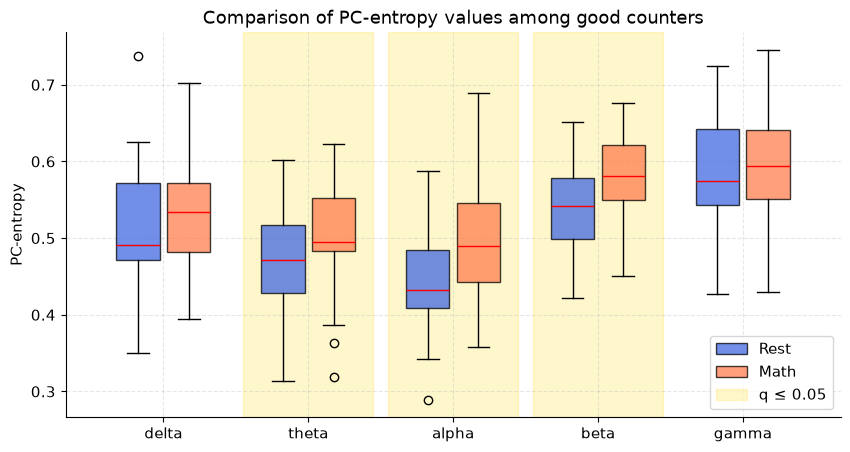

In [ ]:
plot_boxplots(
    pce_rest=pce_rest_gc_waves, 
    pce_task=pce_arithmetic_gc_waves, 
    title='Comparison of PC-entropy values among good counters', 
    significant=measure_differences(pce_rest_gc_waves, pce_arithmetic_gc_waves, EEG_WAVES)
    )

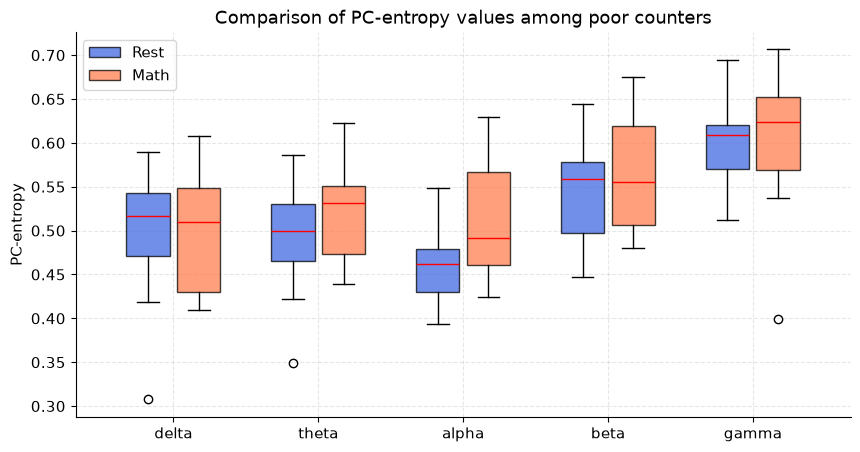

In [ ]:
plot_boxplots(
    pce_rest=pce_rest_pc_waves, 
    pce_task=pce_arithmetic_pc_waves, 
    title='Comparison of PC-entropy values among poor counters',
    significant=significants_pc
    )

In [ ]:
# Creating the indexes vector to filter the channels I want 
first_labels = eegs_rest_df.labels[0]
compare = lambda x: x == first_labels
# Here I assert that labels are equal for all the subjects so I can just take the first
assert eegs_rest_df.labels.apply(compare).count() == 36

labels = first_labels
labels  

['EEG Fp1',
 'EEG Fp2',
 'EEG F3',
 'EEG F4',
 'EEG F7',
 'EEG F8',
 'EEG T3',
 'EEG T4',
 'EEG C3',
 'EEG C4',
 'EEG T5',
 'EEG T6',
 'EEG P3',
 'EEG P4',
 'EEG O1',
 'EEG O2',
 'EEG Fz',
 'EEG Cz',
 'EEG Pz',
 'EEG A2-A1',
 'ECG ECG']

In [ ]:
frontal_channels = {'EEG Fp1', 'EEG Fp2', 'EEG F7', 'EEG F3', 'EEG Fz', 'EEG F4', 'EEG F8'}

frontal_channels_indexes = np.array(list(map(lambda x: x in frontal_channels, labels)), dtype=bool)[:19]
frontal_channels_indexes

array([ True,  True,  True,  True,  True,  True, False, False, False,
       False, False, False, False, False, False, False,  True, False,
       False])

In [ ]:
pce_rest_waves_7 = {
    wave: pc_entropy_sliding_window(filter_wave(eegs_rest[..., frontal_channels_indexes], f), fs=EEG_FS)
    for wave, f in waves_filters.items()
}

pce_arithmetic_waves_7 = {
    wave: pc_entropy_sliding_window(filter_wave(eegs_arithmetic[..., frontal_channels_indexes], f), fs=EEG_FS)
    for wave, f in waves_filters.items()
}

In [ ]:
pce_rest_gc_waves_7, pce_rest_pc_waves_7 = split_poor_good(x=pce_rest_waves_7, good_counters=good_counters)
pce_math_gc_waves_7, pce_math_pc_waves_7 = split_poor_good(x=pce_arithmetic_waves_7, good_counters=good_counters)

In [ ]:
significants_gc_7 = measure_differences(pce_rest_gc_waves_7, pce_math_gc_waves_7, EEG_WAVES)
significants_pc_7 = measure_differences(pce_rest_pc_waves_7, pce_math_pc_waves_7, EEG_WAVES)

print_significance(significants_gc_7)
print_significance(significants_pc_7)

Significant differences (q ≤ 0.05)
-----------------------
alpha : p=0.0002, q=0.0005
beta  : p=0.0000, q=0.0000
theta : p=0.0051, q=0.0086

Significant differences (q ≤ 0.05)
-----------------------
alpha : p=0.0020, q=0.0049
beta  : p=0.0059, q=0.0098
theta : p=0.0020, q=0.0049



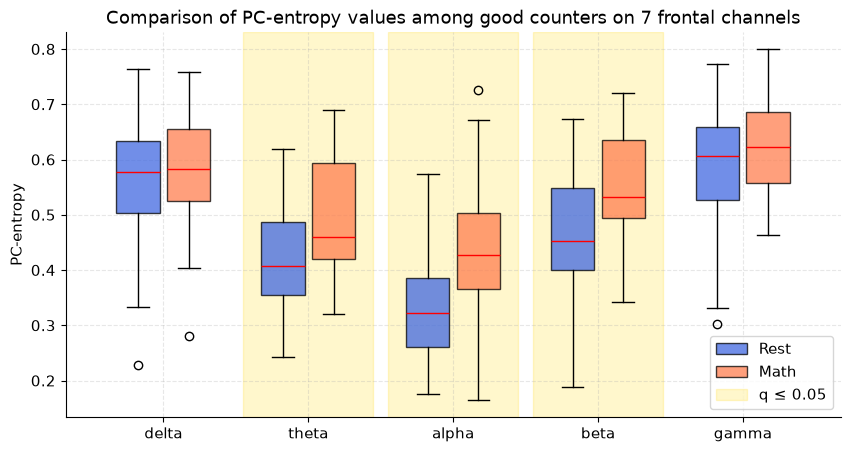

In [ ]:
plot_boxplots(
    pce_rest=pce_rest_gc_waves_7, 
    pce_task=pce_math_gc_waves_7, 
    title='Comparison of PC-entropy values among good counters on 7 frontal channels',
    significant=significants_gc_7
    )

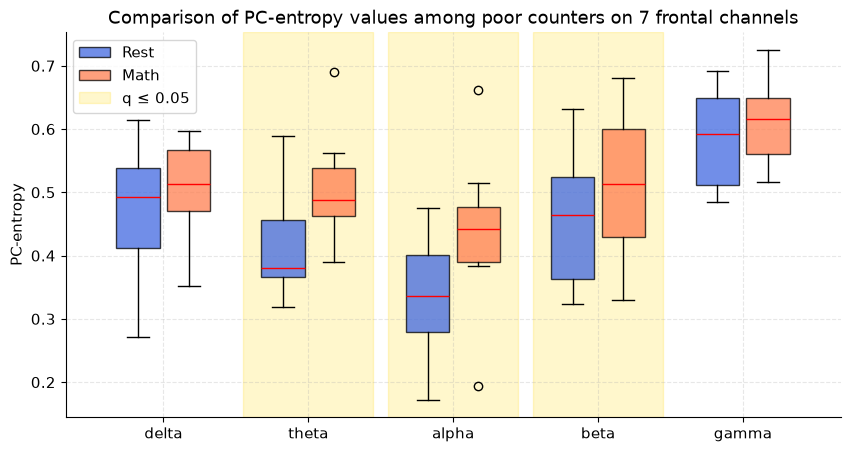

In [ ]:
plot_boxplots(
    pce_rest=pce_rest_pc_waves_7, 
    pce_task=pce_math_pc_waves_7, 
    title='Comparison of PC-entropy values among poor counters on 7 frontal channels',
    significant=significants_pc_7
    )